# Did women win it for Vijay?

**Question:** In Tamil Nadu's 2026 election, did seats where more women voted give TVK more votes?

**Data:** Election Commission of India, 2026 results and gender-wise turnout (my DuckDB),
plus my own city/rural tags for the 12 big-city districts.

**Unit of analysis:** one assembly constituency (234 seats), not one voter.

In [3]:
import duckdb
import pandas as pd

DB = "/Users/justinvanu/Databases/elections/elections.duckdb"

con = duckdb.connect(DB, read_only=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("connected:", con.sql("select count(*) from ac_turnout").fetchone()[0], "rows in ac_turnout")

connected: 234 rows in ac_turnout


**Limit:** seat-level results can't show how individual women voted. Only a survey that asks voters can.


## 1. Know your data
Four tables from my DuckDB. For each: how many rows, how many seats, and what one row means.


In [4]:
tables = ["ac_turnout", "ac_winners", "ac_candidate_results", "tn_ac_district"]

for t in tables:
    rows  = con.sql(f"select count(*) from {t}").fetchone()[0]
    seats = con.sql(f"select count(distinct ac_no) from {t}").fetchone()[0]
    cols  = [c[0] for c in con.sql(f"describe {t}").fetchall()]
    print(f"{t:22s} rows={rows:5d}  seats={seats:3d}  rows per seat={rows/seats:.1f}")
    print("   columns:", ", ".join(cols), "\n")

ac_turnout             rows=  234  seats=234  rows per seat=1.0
   columns: year, ac_no, ac_name, reserved_type, electors_male, electors_female, electors_third_gender, electors_total, overseas_electors, service_electors, evm_votes_male, evm_votes_female, evm_votes_third_gender, postal_votes, test_votes, total_votes, overseas_electors_voted, poll_pct, rejected_postal_votes, rejected_evm_votes, nota_votes, valid_votes, tendered_votes, source 

ac_winners             rows=  234  seats=234  rows per seat=1.0
   columns: year, ac_no, ac_name, reserved_type, winner_name, winner_sex, winner_age, winner_social_category, winner_party, winner_symbol, winner_votes, runner_up_name, runner_up_sex, runner_up_party, runner_up_votes, margin, source 

ac_candidate_results   rows= 4257  seats=234  rows per seat=18.2
   columns: year, ac_no, ac_name, reserved_type, vote_rank, candidate_name, sex, age, category, party, symbol, evm_votes, postal_votes, total_votes, vote_share_pct, pct_of_electors, source 


In [5]:
display(con.sql("""
    SELECT
        COUNT(*)                                                         AS seats,
        COUNT(*) FILTER (WHERE electors_male IS NULL OR electors_female IS NULL
                            OR evm_votes_male IS NULL OR evm_votes_female IS NULL) AS seats_with_blanks,
        COUNT(*) FILTER (WHERE evm_votes_male   > electors_male)         AS seats_men_voted_above_100pct,
        COUNT(*) FILTER (WHERE evm_votes_female > electors_female)       AS seats_women_voted_above_100pct,
        SUM(electors_male)                                               AS electors_men,
        SUM(electors_female)                                             AS electors_women,
        SUM(evm_votes_male)                                              AS evm_votes_men,
        SUM(evm_votes_female)                                            AS evm_votes_women
    FROM ac_turnout
""").df().T)

,0
seats,234.00
seats_with_blanks,0.00
seats_men_voted_above_100pct,0.00
seats_women_voted_above_100pct,0.00
electors_men,28097003.00
electors_women,29307062.00
evm_votes_men,23537143.00
evm_votes_women,25261339.00


In [6]:
# 1. how many TVK rows, and in how many different seats?
display(con.sql("""
    SELECT COUNT(*)              AS tvk_rows,
           COUNT(DISTINCT ac_no) AS seats_with_tvk
    FROM ac_candidate_results
    WHERE party = 'TVK'
""").df())

# 2. which seat has no TVK candidate?
display(con.sql("""
    SELECT t.ac_no, t.ac_name
    FROM ac_turnout t
    LEFT JOIN ac_candidate_results c
           ON c.ac_no = t.ac_no AND c.party = 'TVK'
    WHERE c.ac_no IS NULL
""").df())

# 3. are there party names that look like TVK but aren't?
display(con.sql("""
    SELECT party, COUNT(*) AS candidates, MAX(vote_share_pct) AS best_share
    FROM ac_candidate_results
    WHERE party ILIKE '%t%v%k%'
    GROUP BY party
    ORDER BY candidates DESC
""").df())

,tvk_rows,seats_with_tvk
0,233,233


,ac_no,ac_name
0,86,Edappadi


,party,candidates,best_share
0,TVK,233,58.89
1,tavk,164,6.74
2,VTVTK,26,0.46


In [7]:
# 1. does the winner in ac_winners match the rank-1 candidate in ac_candidate_results?
display(con.sql("""
    WITH top AS (
        SELECT ac_no, party
        FROM ac_candidate_results
        WHERE vote_rank = 1
    )
    SELECT COUNT(*)                                              AS seats,
           COUNT(*) FILTER (WHERE w.winner_party = top.party)    AS winner_matches,
           COUNT(*) FILTER (WHERE w.winner_party = 'TVK')        AS tvk_wins
    FROM ac_winners w
    JOIN top ON top.ac_no = w.ac_no
""").df())

# 2. the five closest results in the state
display(con.sql("""
    SELECT ac_no, ac_name, winner_party, runner_up_party, margin AS margin_votes
    FROM ac_winners
    ORDER BY margin
    LIMIT 5
""").df())

,seats,winner_matches,tvk_wins
0,234,234,108


,ac_no,ac_name,winner_party,runner_up_party,margin_votes
0,185,Tiruppattur,TVK,DMK,1
1,54,Veppanahalli,DMK,ADMK,138
2,229,Kanniyakumari,ADMK,DMK,214
3,66,Polur,TVK,DMDK,227
4,76,Tirukkoyilur,ADMK,TVK,285


## 2. The claim's evidence
The two numbers behind "women won it for Vijay": 17 lakh more women voted,
and women's turnout beat men's in 169 seats. Rebuilding both from the raw data.



In [8]:
display(con.sql("""
    SELECT
        SUM(evm_votes_female)                                            AS women_voted,
        SUM(evm_votes_male)                                              AS men_voted,
        SUM(evm_votes_female) - SUM(evm_votes_male)                      AS extra_women_voters,
        ROUND((SUM(evm_votes_female) - SUM(evm_votes_male)) / 1e5, 2)    AS extra_women_lakh,

        -- statewide turnout: all votes ÷ all electors
        ROUND(100.0 * SUM(evm_votes_female) / SUM(electors_female), 2)   AS women_turnout_pct,
        ROUND(100.0 * SUM(evm_votes_male)   / SUM(electors_male),   2)   AS men_turnout_pct,

        -- the same thing done the wrong way: average of 234 seat turnouts
        ROUND(AVG(100.0 * evm_votes_female / electors_female), 2)        AS women_avg_of_seats,
        ROUND(AVG(100.0 * evm_votes_male   / electors_male),   2)        AS men_avg_of_seats
    FROM ac_turnout
""").df().T)

,0
women_voted,25261339.00
men_voted,23537143.00
extra_women_voters,1724196.00
extra_women_lakh,17.24
women_turnout_pct,86.20
men_turnout_pct,83.77
women_avg_of_seats,86.35
men_avg_of_seats,83.92


In [9]:
display(con.sql("""
    WITH s AS (
        SELECT ac_no, ac_name,
               100.0 * evm_votes_female / electors_female
             - 100.0 * evm_votes_male   / electors_male   AS womens_turnout_lead_pts
        FROM ac_turnout
    )
    SELECT
        COUNT(*)                                              AS seats,
        COUNT(*) FILTER (WHERE womens_turnout_lead_pts > 0)   AS women_ahead,
        COUNT(*) FILTER (WHERE womens_turnout_lead_pts <= 0)  AS men_ahead,
        COUNT(*) FILTER (WHERE womens_turnout_lead_pts >= 5)  AS women_ahead_by_5_plus,
        COUNT(*) FILTER (WHERE womens_turnout_lead_pts > 12)  AS women_ahead_by_over_12,
        COUNT(*) FILTER (WHERE womens_turnout_lead_pts > 13)  AS women_ahead_by_over_13,
        ROUND(MIN(womens_turnout_lead_pts), 2)                AS lowest,
        ROUND(MEDIAN(womens_turnout_lead_pts), 2)             AS typical,
        ROUND(MAX(womens_turnout_lead_pts), 2)                AS highest
    FROM s
""").df().T)

,0
seats,234.00
women_ahead,169.00
men_ahead,65.00
women_ahead_by_5_plus,48.00
women_ahead_by_over_12,8.00
women_ahead_by_over_13,5.00
lowest,-2.78
typical,1.17
highest,13.82


Women’s turnout beat men’s in 169 of 234 seats, by 5+ points in 48. But the typical lead is only 1.17 points. Big leads are rare: 5 seats above 13, 8 above 12.”

In [10]:
lead = con.sql("""
    SELECT t.ac_no, t.ac_name, d.district_name,
           100.0 * t.evm_votes_female / t.electors_female
         - 100.0 * t.evm_votes_male   / t.electors_male   AS womens_turnout_lead_pts
    FROM ac_turnout t
    JOIN tn_ac_district d ON d.ac_no = t.ac_no
""").df()

print("Biggest women's leads")
display(lead.nlargest(10, "womens_turnout_lead_pts").round(2))

print("Where men were furthest ahead")
display(lead.nsmallest(5, "womens_turnout_lead_pts").round(2))

Biggest women's leads


,ac_no,ac_name,district_name,womens_turnout_lead_pts
209,210,Tiruvadanai,RAMANATHAPURAM,13.82
233,234,Killiyoor,KANNIYAKUMARI,13.60
184,185,Tiruppattur,SIVAGANGA,13.12
147,148,Kunnam,PERAMBALUR,13.11
185,186,Sivaganga,SIVAGANGA,13.10
187,188,Melur,MADURAI,12.66
150,151,Tittakudi,CUDDALORE,12.51
175,176,Pattukkottai,THANJAVUR,12.06
220,221,Kadayanallur,TENKASI,11.81
180,181,Thirumayam,PUDUKKOTTAI,11.68


Where men were furthest ahead


,ac_no,ac_name,district_name,womens_turnout_lead_pts
36,37,Kancheepuram,KANCHEEPURAM,-2.78
107,108,Udhagamandalam,THE NILGIRIS,-2.35
122,123,Pollachi,COIMBATORE,-2.29
35,36,Uthiramerur,KANCHEEPURAM,-2.28
55,56,Thalli,KRISHNAGIRI,-2.20


The biggest women’s leads are all in rural seats in the south and the delta (Ramanathapuram, Sivaganga, Pudukkottai…). Men led in the north-west (Kancheepuram, Nilgiris, Coimbatore). The lead follows geography. Possible reason: men working away (to verify)


**Section 2 summary**
- 17,24,196 more women than men cast EVM votes. Turnout: women 86.20%, men 83.77% (lead 2.42 pts).
- Women's turnout beat men's in 169 of 234 seats, but the typical lead is only 1.17 pts.
- Big leads are rare (5 seats above 13 pts, 8 above 12) and all in rural southern and delta seats.


## 3. TVK's result
How many seats TVK won, its share of the vote statewide, and how that share varies from seat to seat.

In [11]:
# 1. seats won by each party
display(con.sql("""
    SELECT winner_party, COUNT(*) AS seats
    FROM ac_winners
    GROUP BY winner_party
    ORDER BY seats DESC
""").df())

# 2. TVK's vote share: statewide, and seat by seat
display(con.sql("""
    WITH all_votes AS (
        SELECT SUM(total_votes)                                   AS votes_cast,
               SUM(total_votes) FILTER (WHERE party = 'TVK')      AS tvk_votes
        FROM ac_candidate_results
    ),
    tvk AS (
        SELECT vote_share_pct FROM ac_candidate_results WHERE party = 'TVK'
    )
    SELECT
        (SELECT tvk_votes FROM all_votes)                                        AS tvk_votes,
        ROUND(100.0 * (SELECT tvk_votes FROM all_votes)
                    / (SELECT votes_cast FROM all_votes), 2)                     AS statewide_share,
        COUNT(*)                                                                 AS seats_contested,
        ROUND(AVG(vote_share_pct), 2)                                            AS avg_of_seats,
        ROUND(MEDIAN(vote_share_pct), 2)                                         AS typical_seat,
        MIN(vote_share_pct)                                                      AS lowest,
        ROUND(QUANTILE_CONT(vote_share_pct, 0.25), 2)                            AS bottom_quarter_below,
        ROUND(QUANTILE_CONT(vote_share_pct, 0.75), 2)                            AS top_quarter_above,
        MAX(vote_share_pct)                                                      AS highest,
        COUNT(*) FILTER (WHERE vote_share_pct >= 40)                             AS seats_40_plus,
        COUNT(*) FILTER (WHERE vote_share_pct < 30)                              AS seats_under_30
    FROM tvk
""").df().T)

,winner_party,seats
0,TVK,108
1,DMK,59
2,ADMK,47
3,INC,5
4,PMK,4
5,VCK,2
6,CPI(M),2
7,IUML,2
8,CPI,2
9,DMDK,1


,0
tvk_votes,17226209.00
statewide_share,34.92
seats_contested,233.00
avg_of_seats,34.88
typical_seat,33.73
lowest,20.32
bottom_quarter_below,29.56
top_quarter_above,40.24
highest,58.89
seats_40_plus,60.00


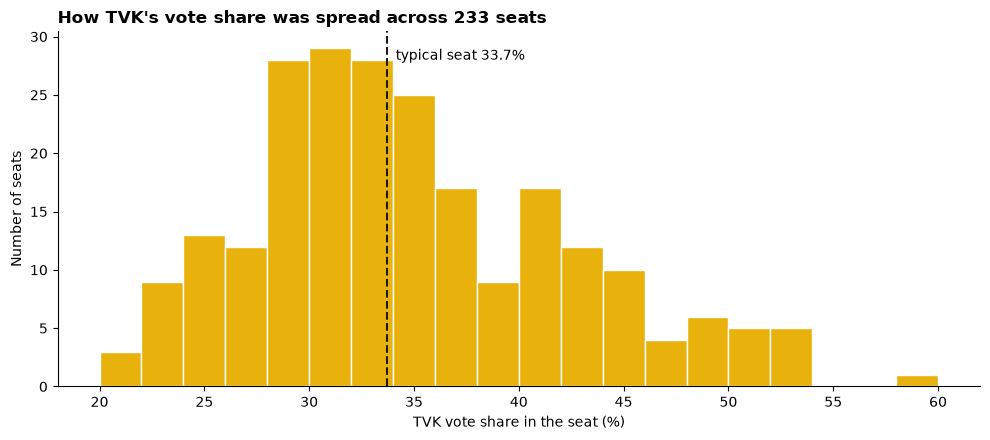

district_name
CHENNAI            13
TIRUVALLUR          9
MADURAI             6
CHENGALPATTU        5
TIRUCHIRAPPALLI     4
SALEM               3
TIRUPPUR            3
KANCHEEPURAM        2
Name: count, dtype: int64

In [12]:
import matplotlib.pyplot as plt

tvk = con.sql("""
    SELECT c.ac_no, c.ac_name, d.district_name, c.vote_share_pct AS tvk_share
    FROM ac_candidate_results c
    JOIN tn_ac_district d ON d.ac_no = c.ac_no
    WHERE c.party = 'TVK'
""").df()

# 1. histogram: how many seats at each level of TVK share
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(tvk.tvk_share, bins=range(20, 62, 2), color="#E9B10C", edgecolor="white")
med = tvk.tvk_share.median()
ax.axvline(med, color="#1C1B19", linestyle="--", linewidth=1.5)
ax.text(med + 0.4, ax.get_ylim()[1] * 0.92, f"typical seat {med:.1f}%", fontsize=10)
ax.set_xlabel("TVK vote share in the seat (%)")
ax.set_ylabel("Number of seats")
ax.set_title("How TVK's vote share was spread across 233 seats", loc="left", fontweight="bold")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

# 2. which districts hold TVK's 40%+ seats?
display(tvk[tvk.tvk_share >= 40].district_name.value_counts().head(8))

Most seats gave TVK 28–36%, with a second group at 40%+. Those strong seats are concentrated in Chennai and big-city districts (Chennai 13, Tiruvallur 9, Madurai 6…). That’s the opposite of where women’s turnout leads were biggest.

**Section 3 summary**
- TVK won 108 seats and 34.9% of all votes; typical seat 33.7%.
- Two groups: most seats 28–36%, plus 60 seats at 40%+, concentrated in Chennai and big-city districts.
- Early hint: TVK's strongest areas aren't where women's turnout leads were biggest.

## 4. One row per seat
Everything needed for the tests, side by side: TVK's share, the winner, turnout by gender, and my city/rural tags.

In [13]:
seats = con.sql("""
    WITH tvk AS (
        SELECT ac_no, vote_share_pct AS tvk_share
        FROM ac_candidate_results
        WHERE party = 'TVK'                            -- one row per seat (checked in Section 1)
    ),
    tags AS (
        SELECT * FROM read_csv('../input/city_rural_tags.csv')
    )
    SELECT
        t.ac_no, t.ac_name, d.district_name, g.region, g.area_class,
        w.winner_party, tvk.tvk_share,
        t.electors_male, t.electors_female,
        t.evm_votes_male                               AS voters_male,
        t.evm_votes_female                             AS voters_female,
        t.evm_votes_third_gender                       AS voters_tg,
        100.0 * t.evm_votes_male   / t.electors_male   AS men_turnout_pct,
        100.0 * t.evm_votes_female / t.electors_female AS women_turnout_pct,
        100.0 * t.evm_votes_female / t.electors_female
      - 100.0 * t.evm_votes_male   / t.electors_male   AS womens_turnout_lead_pts,
        t.evm_votes_female - t.evm_votes_male          AS extra_women_voters,
        100.0 * t.evm_votes_female
              / (t.evm_votes_female + t.evm_votes_male + t.evm_votes_third_gender) AS women_per_100_voters,
        w.margin                                       AS margin_votes
    FROM ac_turnout t
    JOIN ac_winners w     ON w.ac_no = t.ac_no
    JOIN tn_ac_district d ON d.ac_no = t.ac_no
    LEFT JOIN tvk         ON tvk.ac_no = t.ac_no       -- LEFT keeps Edappadi, which has no TVK row
    LEFT JOIN tags g      ON g.ac_no = t.ac_no         -- LEFT keeps the 130 untagged seats
    ORDER BY t.ac_no
""").df()

# checks: the shape, no duplicates, and where the blanks are
print("rows, columns:", seats.shape)
print("duplicate seats:", seats.ac_no.duplicated().sum())
display(seats.isna().sum()[lambda s: s > 0])
display(seats.head())

rows, columns: (234, 18)
duplicate seats: 0


region        130
area_class    130
tvk_share       1
dtype: int64

,ac_no,ac_name,district_name,region,area_class,winner_party,tvk_share,electors_male,electors_female,voters_male,voters_female,voters_tg,men_turnout_pct,women_turnout_pct,womens_turnout_lead_pts,extra_women_voters,women_per_100_voters,margin_votes
0,1,Gummidipoondi,TIRUVALLUR,CHENNAI METRO,rural,TVK,40.56,123403,130736,112919,117961,20,91.50,90.23,-1.28,5042,51.09,27945
1,2,Ponneri,TIRUVALLUR,CHENNAI METRO,rural,TVK,48.69,122315,129071,111156,114495,25,90.88,88.71,-2.17,3339,50.73,55768
2,3,Tiruttani,TIRUVALLUR,CHENNAI METRO,rural,ADMK,34.91,130026,132449,116310,119297,13,89.45,90.07,0.62,2987,50.63,5793
3,4,Thiruvallur,TIRUVALLUR,CHENNAI METRO,rural,TVK,40.71,122289,128786,110302,114331,16,90.20,88.78,-1.42,4029,50.89,24760
4,5,Poonamallee,TIRUVALLUR,CHENNAI METRO,mixed,TVK,52.22,179193,189432,150326,156720,34,83.89,82.73,-1.16,6394,51.04,72740


In [14]:
seats.to_csv("../output/seats_2026.csv", index=False)

**Section 4 summary**
- Built one table with one row per seat (234), joining turnout, winners, district, TVK's share and my tags.
- Checked: no duplicate seats; blanks only where expected (Edappadi TVK share; 130 untagged seats).
- Saved to output/seats_2026.csv.

## 5. Women vs TVK
The test: did seats with a bigger women's turnout lead give TVK a bigger vote share?
Picture first, then the numbers.

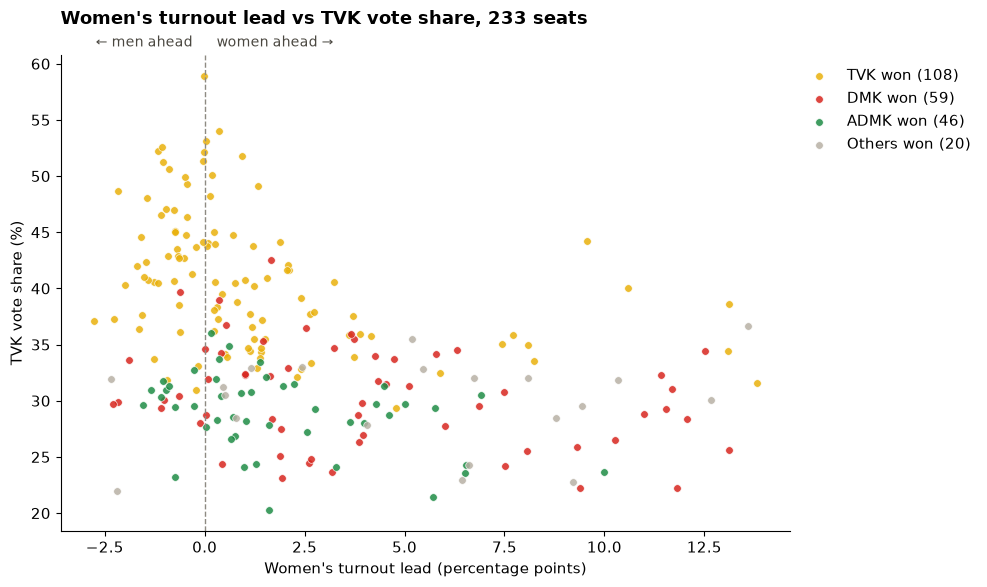

In [23]:
import matplotlib.pyplot as plt

PARTY = {"TVK": "#E9B10C", "DMK": "#D7261E", "ADMK": "#1E8C45"}
OTHER = "#B8B1A5"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

df = seats.dropna(subset=["tvk_share"]).copy()
df["won_by"] = df.winner_party.where(df.winner_party.isin(PARTY), "Others")

fig, ax = plt.subplots(figsize=(10, 6))
for party in ["TVK", "DMK", "ADMK", "Others"]:
    g = df[df.won_by == party]
    ax.scatter(g.womens_turnout_lead_pts, g.tvk_share, s=30, alpha=0.85,
               color=PARTY.get(party, OTHER), edgecolor="white", linewidth=0.5,
               label=f"{party} won ({len(g)})")

ax.axvline(0, color="#8E8A82", linewidth=1, linestyle="--")          # left of 0: men ahead, right: women ahead
top = ax.get_xaxis_transform()                                       # x in data units, y in axes units (0–1)
ax.text( 0.3, 1.01, "women ahead →", transform=top, fontsize=10, color="#4A4740", va="bottom")
ax.text(-0.3, 1.01, "← men ahead",   transform=top, fontsize=10, color="#4A4740", va="bottom", ha="right")

ax.set_xlabel("Women's turnout lead (percentage points)")
ax.set_ylabel("TVK vote share (%)")
ax.set_title("Women's turnout lead vs TVK vote share, 233 seats", loc="left", fontweight="bold", pad=22)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
fig.savefig("../output/scatter_lead_vs_tvk.png", dpi=150)
plt.show()

No upward pattern. TVK’s best seats are where men and women voted about equally. Where women’s lead was biggest, TVK mostly got 22–35% and other parties won.

In [24]:
stair = con.sql("""
    WITH g AS (
        SELECT *,
               NTILE(5) OVER (ORDER BY womens_turnout_lead_pts DESC) AS grp   -- 1 = biggest women's lead
        FROM seats
    )
    SELECT grp,
           COUNT(*)                                        AS seats,
           ROUND(MIN(womens_turnout_lead_pts), 2)          AS lead_from,
           ROUND(MAX(womens_turnout_lead_pts), 2)          AS lead_to,
           COUNT(*) FILTER (WHERE winner_party = 'TVK')    AS tvk_won,
           ROUND(MEDIAN(tvk_share), 1)                     AS typical_tvk_share
    FROM g
    GROUP BY grp
    ORDER BY grp
""").df()
display(stair)

,grp,seats,lead_from,lead_to,tvk_won,typical_tvk_share
0,1,47,5.12,13.82,10,30.50
1,2,47,1.92,5.01,16,31.80
2,3,47,0.51,1.90,23,34.20
3,4,47,-0.63,0.45,29,39.30
4,5,46,-2.78,-0.64,30,39.40


Five equal groups by women’s lead: TVK won 10, 16, 23, 29, 30, rising as women’s lead shrinks. The opposite of what the claim predicts.

In [25]:
# correlation by hand: the same 4 steps as before, now for women's turnout lead
c = seats.dropna(subset=["tvk_share"])[["ac_name", "womens_turnout_lead_pts", "tvk_share"]].copy()
c.columns = ["seat", "x", "y"]                  # x = women's turnout lead, y = TVK share

c["dx"] = c.x - c.x.mean()                      # step 1: how far from average
c["dy"] = c.y - c.y.mean()
c["product"] = c.dx * c.dy                      # step 2: + agrees with the claim, − disagrees
covariance = c["product"].sum() / (len(c) - 1)  # step 3: average agreement
r = covariance / (c.x.std() * c.y.std())        # step 4: scale to −1 … +1

print(f"seats agreeing: {(c['product'] > 0).sum()}   disagreeing: {(c['product'] < 0).sum()}")
print(f"covariance  = {covariance:.2f}")
print(f"r (by hand) = {r:.3f}    pandas check = {c.x.corr(c.y):.3f}")

seats agreeing: 87   disagreeing: 146
covariance  = -11.13
r (by hand) = -0.387    pandas check = -0.387


Pearson r = −0.39: a moderate negative link. 146 seats go against the claim and 87 support it. Stronger than women per 100 (−0.20), possibly because the turnout lead tracks geography more closely; tested in Section 6.

In [26]:
# Spearman = the same correlation, but on rank positions instead of raw values
c["x_rank"] = c.x.rank()        # 1 = smallest women's lead … 233 = biggest
c["y_rank"] = c.y.rank()        # 1 = TVK's weakest seat … 233 = strongest

rho = c.x_rank.corr(c.y_rank)   # Pearson on the ranks = Spearman
print(f"Spearman (by hand) = {rho:.3f}    pandas check = {c.x.corr(c.y, method='spearman'):.3f}")

display(c.sort_values("x", ascending=False)[["seat", "x", "x_rank", "y", "y_rank"]].head(5).round(2))

Spearman (by hand) = -0.427    pandas check = -0.427


,seat,x,x_rank,y,y_rank
209,Tiruvadanai,13.82,233.00,31.57,87.00
233,Killiyoor,13.60,232.00,36.68,154.00
184,Tiruppattur,13.12,231.00,38.65,168.00
147,Kunnam,13.11,230.00,25.66,24.00
185,Sivaganga,13.10,229.00,34.45,129.00


Spearman (ranks) = −0.43, close to Pearson’s −0.39, so outliers aren’t driving it. Individual seats vary (Kunnam: lead rank 230, TVK rank 24), but the overall tilt is negative.

In [27]:
measures = {
    "Women's turnout lead":    "womens_turnout_lead_pts",   # women's rate − men's rate
    "Women minus men (count)": "extra_women_voters",        # head count difference
    "Women per 100 voters":    "women_per_100_voters",      # share of the voting crowd
    "Women's turnout (alone)": "women_turnout_pct",         # men aren't in this one at all
}

df = seats.dropna(subset=["tvk_share"])
rows = []
for label, col in measures.items():
    rows.append({
        "measure":  label,
        "pearson":  df[col].corr(df.tvk_share),
        "spearman": df[col].corr(df.tvk_share, method="spearman"),
    })

display(pd.DataFrame(rows).set_index("measure").round(2))

,pearson,spearman
measure,,
Women's turnout lead,-0.39,-0.43
Women minus men (count),-0.17,-0.21
Women per 100 voters,-0.20,-0.23
Women's turnout (alone),-0.35,-0.33


**Section 5 summary**
- Scatter: no upward pattern. TVK's best seats are where men and women voted about equally.
- Staircase by women's lead: TVK won 10, 16, 23, 29, 30 seats (most women → fewest).
- Correlation with women's turnout lead: Pearson −0.39, Spearman −0.43.
- Same direction for all four measures (−0.17 to −0.43).
- Open question: is this about women, or about where these seats are? → Section 6.

## 6. Geography
Is "city vs village" behind both TVK's share and the women's lead?
Uses my city/rural tags (104 seats in 12 big-city districts).

In [28]:
display(con.sql("""
    SELECT area_class,
           COUNT(*)                                        AS seats,
           COUNT(*) FILTER (WHERE winner_party = 'TVK')    AS tvk_won,
           ROUND(MEDIAN(tvk_share), 1)                     AS typical_tvk_share,
           ROUND(MEDIAN(womens_turnout_lead_pts), 2)       AS typical_womens_lead,
           ROUND(MEDIAN(women_turnout_pct), 1)             AS typical_women_turnout
    FROM seats
    WHERE area_class IS NOT NULL
    GROUP BY area_class
    ORDER BY typical_tvk_share DESC
""").df())

,area_class,seats,tvk_won,typical_tvk_share,typical_womens_lead,typical_women_turnout
0,city,43,38,44.70,-0.45,82.80
1,mixed,13,12,42.00,0.41,85.70
2,rural,48,21,32.70,0.22,88.70


City seats gave TVK 44.7% (won 38 of 43), rural 32.7% (21 of 48): a 12-point gap. Women’s lead hardly differs between them here. Cities have lower turnout overall, which explains the negative link for women’s turnout on its own.

In [29]:
display(con.sql("""
    SELECT area_class,
           CASE WHEN womens_turnout_lead_pts > 0 THEN 'women ahead' ELSE 'men ahead' END AS turnout,
           COUNT(*)                                      AS seats,
           ROUND(MEDIAN(tvk_share), 2)                   AS typical_tvk_share
    FROM seats
    WHERE area_class IN ('city', 'rural')
      AND tvk_share IS NOT NULL
    GROUP BY ALL
    ORDER BY area_class, turnout
""").df())

,area_class,turnout,seats,typical_tvk_share
0,city,men ahead,28,45.06
1,city,women ahead,15,43.95
2,rural,men ahead,22,31.58
3,rural,women ahead,25,33.34


In [30]:
display(con.sql("""
    SELECT region,
           COUNT(*) FILTER (WHERE area_class = 'city')                                AS city_seats,
           COUNT(*) FILTER (WHERE area_class = 'rural' AND tvk_share IS NOT NULL)     AS rural_seats,
           ROUND(MEDIAN(tvk_share) FILTER (WHERE area_class = 'city'), 1)             AS city_tvk,
           ROUND(MEDIAN(tvk_share) FILTER (WHERE area_class = 'rural'), 1)            AS rural_tvk,
           ROUND(MEDIAN(tvk_share) FILTER (WHERE area_class = 'city')
               - MEDIAN(tvk_share) FILTER (WHERE area_class = 'rural'), 1)            AS city_minus_rural
    FROM seats
    WHERE region IS NOT NULL
    GROUP BY region
    ORDER BY city_minus_rural DESC
""").df())

,region,city_seats,rural_seats,city_tvk,rural_tvk,city_minus_rural
0,THOOTHUKKUDI,1,5,49.10,33.30,15.80
1,TIRUPPUR,2,6,45.50,30.20,15.30
2,MADURAI,4,4,43.40,29.70,13.70
3,SALEM,3,7,44.00,31.90,12.00
4,TIRUCHIRAPPALLI,2,5,46.30,34.40,11.90
5,ERODE,2,6,43.30,32.30,11.10
6,CHENNAI METRO,25,7,46.50,37.30,9.30
7,COIMBATORE,3,4,38.10,30.50,7.50
8,TIRUNELVELI,1,3,36.50,35.00,1.50


City seats beat rural seats for TVK in all 9 regions, by 1.5 to 15.8 points. Thoothukkudi and Tirunelveli have only one city seat each, so treat those as rough.

In [31]:
cols = ["womens_turnout_lead_pts", "extra_women_voters", "women_per_100_voters", "women_turnout_pct", "tvk_share"]
df = seats.dropna(subset=["tvk_share"])

# each seat minus its own district's typical (median) seat, for every column
within = df[cols] - df.groupby("district_name")[cols].transform("median")

rows = []
for col in cols[:-1]:
    rows.append({
        "measure":         col,
        "all_seats":       df[col].corr(df.tvk_share, method="spearman"),
        "within_district": within[col].corr(within.tvk_share, method="spearman"),
    })
display(pd.DataFrame(rows).set_index("measure").round(2))

,all_seats,within_district
measure,,
womens_turnout_lead_pts,-0.43,-0.19
extra_women_voters,-0.21,0.02
women_per_100_voters,-0.23,-0.06
women_turnout_pct,-0.33,-0.43


**Section 6 summary**
- City seats gave TVK 44.7% (won 38 of 43), rural seats 32.7% (21 of 48): a 12-point gap.
- Holding city/rural fixed, women-ahead vs men-ahead moves TVK only 1–2 points, in no consistent direction.
- City beats rural in all 9 regions (1.5 to 15.8 points).
- Comparing within districts, most of the women-vs-TVK link fades. Geography explains most of it.

## 7. Putting it together
A regression estimates the effect of women's lead on TVK's share while holding
city/rural and region fixed. Built up in steps: first women's lead alone, then adding geography.

In [32]:
%pip install statsmodels

  Using cached statsmodels-0.15.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
Using cached statsmodels-0.15.0-cp312-cp312-macosx_11_0_arm64.whl (11.5 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [33]:
import statsmodels.formula.api as smf

m1 = smf.ols("tvk_share ~ womens_turnout_lead_pts", data=seats).fit()

print(m1.summary().tables[1])
print(f"seats used: {int(m1.nobs)}   R² = {m1.rsquared:.3f}")

                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  36.7413      0.542     67.769      0.000      35.673      37.810
womens_turnout_lead_pts    -0.7637      0.120     -6.372      0.000      -1.000      -0.528
seats used: 233   R² = 0.149


In [34]:
tagged = seats[seats.area_class.notna()]      # the 104 seats with my city/rural tags

models = {
    "1. lead only (all seats)":    ("tvk_share ~ womens_turnout_lead_pts", seats),
    "2. lead only (12 districts)": ("tvk_share ~ womens_turnout_lead_pts", tagged),
    "3. + region":                 ("tvk_share ~ womens_turnout_lead_pts + C(region)", tagged),
    "4. + region + city/rural":    ("tvk_share ~ womens_turnout_lead_pts + C(region)"
                                    " + C(area_class, Treatment('rural'))", tagged),
}

rows = []
for name, (formula, data) in models.items():
    m = smf.ols(formula, data=data).fit()
    lo, hi = m.conf_int().loc["womens_turnout_lead_pts"]
    rows.append({
        "model":       name,
        "seats":       int(m.nobs),
        "lead_effect": m.params["womens_turnout_lead_pts"],
        "likely_low":  lo,
        "likely_high": hi,
        "p_value":     m.pvalues["womens_turnout_lead_pts"],
        "R2":          m.rsquared,
    })
display(pd.DataFrame(rows).set_index("model").round(2))

# the last model (m) also gives the city effect
print(m.params.filter(like="area_class").round(2))
print(m.conf_int().filter(like="area_class", axis=0).round(2))

,seats,lead_effect,likely_low,likely_high,p_value,R2
model,,,,,,
1. lead only (all seats),233,-0.76,-1.00,-0.53,0.00,0.15
2. lead only (12 districts),103,-1.08,-1.71,-0.44,0.00,0.10
3. + region,103,-0.93,-1.74,-0.11,0.03,0.35
4. + region + city/rural,103,-0.33,-0.93,0.28,0.28,0.67


C(area_class, Treatment('rural'))[T.city]    10.47
C(area_class, Treatment('rural'))[T.mixed]    7.12
dtype: float64
                                              0     1
C(area_class, Treatment('rural'))[T.city]  8.26 12.67
C(area_class, Treatment('rural'))[T.mixed] 3.95 10.28


**Section 7 summary**
- Women's lead alone: −0.76 per point. After region and city/rural: −0.33, range −0.93 to +0.28 (no clear link).
- City seats: +10.5 points for TVK (8.3 to 12.7) vs rural seats in the same region. Mixed: +7.1.
- Geography explains two-thirds of the seat-to-seat differences (R² 0.67).
- The data rules out a large positive women's effect, but can't prove it's exactly zero.

## 8. Limits and checks
1. Does the result change if we measure "more women" another way, including one that men working away can't affect?
2. Could the extra women voters have decided any of TVK's seats?
3. What this data cannot tell us.

In [36]:
others = {
    "Women's turnout lead":    "womens_turnout_lead_pts",
    "Women per 100 voters":    "women_per_100_voters",
    "Women's turnout (alone)": "women_turnout_pct",     # no men in this one, so men working away can't affect it
}

rows = []
for label, col in others.items():
    formula = f"tvk_share ~ {col} + C(region) + C(area_class, Treatment('rural'))"
    m = smf.ols(formula, data=tagged).fit()
    lo, hi = m.conf_int().loc[col]
    rows.append({
        "measure":          label,
        "effect_per_point": m.params[col],
        "likely_low":       lo,
        "likely_high":      hi,
        "p_value":          m.pvalues[col],
    })

display(pd.DataFrame(rows).set_index("measure").round(2))

,effect_per_point,likely_low,likely_high,p_value
measure,,,,
Women's turnout lead,-0.33,-0.93,0.28,0.28
Women per 100 voters,-0.64,-2.14,0.85,0.39
Women's turnout (alone),-0.04,-0.35,0.28,0.82


ame model with three measures: all ranges include zero. Women’s turnout alone (immune to men working away) gives −0.04 (−0.35 to +0.28), so migration isn’t hiding an effect

In [37]:
tvk_wins = seats[seats.winner_party == "TVK"].copy()

# extra women who voted only because women's turnout beat men's (0 where men were ahead)
tvk_wins["extra_from_turnout"] = (
    (tvk_wins.women_turnout_pct - tvk_wins.men_turnout_pct) / 100 * tvk_wins.electors_female
).clip(lower=0)

checks = {
    "all extra women (women − men)":        tvk_wins.extra_women_voters > tvk_wins.margin_votes,
    "extra women from higher turnout only": tvk_wins.extra_from_turnout > tvk_wins.margin_votes,
}
for label, could_decide in checks.items():
    print(f"{label:38s} bigger than TVK's margin in {could_decide.sum():3d} of {len(tvk_wins)} wins")

print(f"\ntypical TVK winning margin:  {tvk_wins.margin_votes.median():>7,.0f} votes")
print(f"typical extra women voters:  {tvk_wins.extra_women_voters.median():>7,.0f}")

all extra women (women − men)          bigger than TVK's margin in  29 of 108 wins
extra women from higher turnout only   bigger than TVK's margin in  13 of 108 wins

typical TVK winning margin:   15,969 votes
typical extra women voters:    6,218


Extreme case: if every extra woman voted TVK, they could have decided at most 29 of TVK’s 108 wins (13 counting only extra turnout). In 79+ wins, the margin was bigger than all extra women combined. Typical margin ~16,000; typical extra women ~6,200.


### What this data cannot tell us
- **How individual women voted.** Results are counted by seat, not by voter. Only a post-poll survey split by gender can answer that. None found so far.
- **A gender gap that's the same everywhere.** If women everywhere leaned TVK by a few points, seat data couldn't detect it, because women's share of voters barely varies between seats.
- **City/rural tags are my judgment.** To verify against the 2008 Delimitation order. They cover only the 12 big-city districts (104 seats).
- **Men working away** likely inflates the women's lead in southern and delta seats. A hypothesis, to be confirmed with a source.
- **Booth-level hint:** in Dharapuram, booths with more women on the roll leaned slightly TVK (+0.7 pts). One seat, but it's the finest-grained test so far, and it points the other way.
- **Tiruppattur's 1-vote margin:** to verify with ECI.

**Section 8 summary**
- With city/rural and region held fixed, no measure of "more women" shows a clear link, including women's turnout alone, which men working away can't affect.
- Extra women voters could have decided at most 29 of TVK's 108 wins, and only under an extreme assumption.
- Limits listed above. The data can't show how individual women voted.

## 9. Conclusion

**The answer, in one or two sentences:**
(Did the data support "women won it for Vijay"? Be careful about what it can and can't say.)

**What the evidence shows:**
- 
- 
- 

**What it doesn't show:**
- 

**What would settle it:**
-